# FASE 1. DEFINICIÓN DEL PROBLEMA Y CONFIGURACIÓN DEL ENTORNO CIENTÍFICO

**Magíster en Ciencia de Datos e Inteligencia Artificial**  
**Asignatura:** Programación para la Ciencia de Datos (MCDI500)  
**Grupo:** 7

**Integrantes:** 
- Jairo Barraza Salazar 
- Javier Huamanni Barrera
- Jean Salas Meneses
- Pavel Chávez San Martín  

**Docente:** Dr. Omar Salinas Silva

---

## Título del proyecto

**Exposición operacional documentada de las 15 comunas más pobladas de Chile a las fallas del Sistema Eléctrico Nacional (2024–2026)**

## 1. Contextualización

La continuidad del suministro eléctrico condiciona el funcionamiento de hogares, servicios públicos, establecimientos de salud, actividades productivas y otras funciones territoriales. Por ello, el estudio de las fallas del Sistema Eléctrico Nacional (SEN) adquiere una dimensión adicional cuando se pregunta **dónde se registra la afectación del consumo y cuáles comunas presentan una mayor exposición documental a estos eventos**.

La **Norma Técnica de Calidad de Servicio para Sistemas de Distribución** distingue la frecuencia y la duración de las interrupciones efectivamente experimentadas por los clientes, y define indicadores como SAIFI y SAIDI a partir de cantidades de clientes afectados y tiempos de interrupción (Comisión Nacional de Energía [CNE], 2024). Este marco obliga a diferenciar **una falla o indisponibilidad de instalaciones del SEN** de **una interrupción de suministro comprobada para usuarios de una comuna**. No son magnitudes equivalentes.

Los informes mensuales publicados por el Coordinador Eléctrico Nacional (CEN) contienen campos útiles para estudiar esa relación, entre ellos `Comuna`, `Zona Afectada`, `Consumo`, `Distribuidoras Afectadas`, las fechas y características técnicas del evento. El campo `Comuna` puede mencionar **más de una comuna, separadas por `|`**; por tanto, requiere tratamiento específico antes de elaborar comparaciones territoriales. La fuente y su cobertura mensual se documentan en el portal del CEN (Coordinador Eléctrico Nacional, s. f.).

El conjunto consolidado disponible para este proyecto integra **33 publicaciones mensuales, de enero de 2024 a septiembre de 2026**, mediante un procedimiento reproducible en Python. La validación estructural inicial informó **18.019 registros y 40 variables**. Estas cifras representan el universo documental inicial, **no 18.019 cortes de suministro ni 18.019 eventos independientes con clientes afectados**.

En este proyecto, **«comunas prioritarias» designa exclusivamente a las 15 comunas con mayor población censada en el Censo 2024**. El término no implica un criterio de vulnerabilidad, criticidad ni prioridad de política pública. Para seleccionarlas se utiliza, como criterio único y verificable, la **población censada por comuna en el Censo 2024** del Instituto Nacional de Estadísticas (INE). Esta fuente ofrece datos territoriales comparables y permite evitar selecciones subjetivas. El tamaño de la población se utilizará como criterio de selección o variable contextual, **no como equivalente al número de personas que sufrió una interrupción** (Instituto Nacional de Estadísticas [INE], 2025).

## 2. Definición del problema

Aunque existen registros sobre fallas del SEN, su disponibilidad no permite responder directamente qué comunas han sufrido una mayor indisponibilidad de suministro. Los informes describen sucesos técnicos y administrativos con diferentes estados, fechas y niveles de detalle. Además, un registro puede mencionar varias comunas, declarar consumo no afectado o corresponder a una actualización de información previamente publicada.

El problema no consiste solamente en contar fallas. **Consiste en establecer una metodología verificable para vincular los eventos documentados con las comunas mencionadas, identificar cuándo se reporta afectación del consumo y comparar territorialmente la exposición a esos eventos sin confundirla con la duración real de los cortes sufridos por los usuarios.**

La falta de normalización de nombres comunales, la presencia de valores faltantes, la diferencia entre fechas de perturbación y reposición y la ausencia de número de clientes afectados en el CSV principal imponen límites relevantes a las inferencias. Estas restricciones deben resolverse o declararse antes de construir un indicador de impacto territorial.

## 3. Pregunta de investigación

**Pregunta analítica**

**¿Cómo se distribuye la exposición operacional documentada a fallas del Sistema Eléctrico Nacional entre las 15 comunas más pobladas de Chile (Censo 2024), entre enero de 2024 y septiembre de 2026? La exposición se mide como la frecuencia de informes del CEN en relación con la población de cada comuna, la recurrencia temporal y la duración documental de esos informes. ¿Qué parte de esa exposición corresponde a eventos con afectación de consumo reportada?**

La pregunta compara territorios a partir de registros documentales y **no atribuye interrupciones efectivas a los usuarios** (§4.1). Es la pregunta **analítica** del proyecto: se responde con los indicadores de la §6.6. La pregunta de enfoque del mapa conceptual (§9.1), en cambio, es **metodológica**: describe el flujo de trabajo que permite responder esta.

**Preguntas complementarias:** ¿qué proporción de los informes menciona comunas identificables?, ¿qué categorías de consumo se reportan?, ¿qué tipos de instalaciones y causas están asociadas a los eventos?, ¿cuánto cambia el resultado cuando se restringe el análisis a registros técnicamente válidos?, ¿qué información adicional sería necesaria para medir SAIDI, SAIFI o clientes-hora interrumpidos por comuna?

## 4. Justificación del proyecto

### 4.1. Justificación territorial y operacional

El análisis tradicional centrado en el activo permite describir fallas, pero no muestra necesariamente **cómo se distribuyen territorialmente los antecedentes de afectación del consumo**. Incorporar la comuna como unidad de observación secundaria hace posible examinar desigualdades en la concentración de eventos documentados y priorizar territorios para una revisión más profunda.

La distinción regulatoria es esencial: la CNE (2024) define los indicadores de calidad de suministro a partir de **interrupciones que experimentan los clientes**; el número de informes de falla del CEN no reproduce esa medición. En consecuencia, esta investigación utilizará inicialmente indicadores de **exposición operacional documentada** y no presentará sus resultados como SAIDI, SAIFI, cantidad de usuarios afectados ni pérdidas económicas observadas.

El indicador público SAIDI difundido por la Superintendencia de Electricidad y Combustibles (SEC) permitirá aportar contexto y comprobar las diferencias entre una métrica regulatoria y la caracterización documental propuesta. La SEC distingue interrupciones por causas internas, externas y fuerza mayor; esa clasificación no debe igualarse automáticamente a las categorías del CSV del CEN (Superintendencia de Electricidad y Combustibles [SEC], s. f.).

### 4.2. Justificación de la selección de comunas

La expresión **«comunas más relevantes»** requiere un criterio reproducible. Se propone seleccionar como grupo principal las **15 comunas con mayor población censada a nivel nacional en 2024**, utilizando una tabla oficial del INE que incluya nombre, región, código comunal y población. La lista definitiva se generará por programación una vez incorporada dicha tabla: no se asignarán posiciones sin verificar la fuente.

La población permite seleccionar territorios de alta concentración de habitantes, pero no demuestra mayor consumo eléctrico, exposición individual, criticidad sanitaria o impacto económico. Una segunda comparación con comunas de relevancia productiva o de infraestructura crítica **solo se incorporará si se define previamente un indicador externo, verificable y comparable**. Los resultados del Censo 2024 permiten disponer de una base territorial pública para esta decisión (INE, 2025).

### 4.3. Justificación desde la ciencia de datos

La asociación entre registros y comunas exige un flujo de procesamiento que no se resuelve mediante un recuento simple. Deben separarse los nombres compuestos de `Comuna`, normalizarse las denominaciones mediante códigos comunales oficiales, conservarse la relación de muchos-a-muchos entre informes y territorios y verificarse los indicadores con y sin afectación declarada de consumo.

Los campos `Consumo`, `Estado` y `Fecha Efectiva Fin` requieren interpretación conjunta. La documentación de pandas distingue las acciones de identificar, eliminar e imputar ausencias; ninguna constituye, por sí sola, una justificación técnica para modificar registros (pandas development team, s. f.-b). Por ello, una fecha de término ausente no se rellenará artificialmente y `consumo_no_afectado` no se contabilizará como interrupción de clientes.

El enfoque de Silva et al. (2025), basado en registros de fallas de distribución eléctrica, respalda la utilidad de examinar conjuntamente recurrencia, causas y localización. **Su sistema de estudio es distinto del SEN chileno**, por lo que sus hallazgos no se extrapolarán; se aprovecha únicamente su fundamento metodológico de análisis territorial y multivariable.

### 4.4. Justificación científica y académica

El proyecto permite aplicar programación modular, funciones, tratamiento de datos tabulares, validación, visualizaciones y control de versiones en un caso territorial de relevancia pública. Además, obliga a distinguir entre **dato observado**, **indicador construido** e **interpretación del impacto**, habilidad crítica en ciencia de datos.

Los principios FAIR para software de investigación destacan la importancia de documentar dependencias, procedencia y condiciones de reutilización (Barker et al., 2022). En este caso, la trazabilidad debe conservar la ruta del archivo mensual, el número del informe, las comunas mencionadas originalmente, las reglas de expansión territorial y las decisiones de inclusión/exclusión.

### 4.5. Valor previsto y límites de la contribución

El proyecto busca producir una **comparación territorial transparente**, tablas y visualizaciones de concentración de informes con afectación de consumo reportada, recurrencias y perfiles operacionales por comuna prioritaria. Su utilidad radica en orientar preguntas de verificación para estudios posteriores y no en certificar cuánto tiempo quedó sin energía cada residente.

La principal contribución será distinguir **evidencia de ocurrencia reportada** de **impacto efectivo en consumidores**, dejando explícita la información adicional necesaria para pasar del primer nivel al segundo.

## 5. Objetivos del proyecto

### 5.1. Objetivo general

**Analizar comparativamente la exposición operacional documentada a eventos de falla del Sistema Eléctrico Nacional en las 15 comunas de mayor población censada de Chile, considerando los informes publicados entre enero de 2024 y septiembre de 2026, mediante procedimientos reproducibles de ciencia de datos que permitan caracterizar la frecuencia, recurrencia, afectación de consumo reportada y duración documental válida de los eventos, con resultados y límites de interpretación claramente identificados.**

### 5.2. Objetivos específicos

**OE1. Integrar las fuentes documentales y territoriales del estudio.**

Integrar las 33 publicaciones mensuales de informes de falla del CEN con una tabla oficial del Censo 2024 del INE, conservando identificadores, procedencia y variables originales, durante la preparación inicial y F2.

**OE2. Depurar y vincular los registros con las comunas.**

Depurar los 18.019 registros iniciales y normalizar los campos `Comuna`, `Consumo`, `Estado` y fechas, resolviendo listas multicomuna y validando la correspondencia con códigos comunales oficiales, para obtener un conjunto territorial trazable al cierre de F2.

**OE3. Seleccionar y caracterizar las comunas prioritarias.**

Seleccionar las 15 comunas de mayor población censada nacional en 2024 y caracterizar la cobertura, completitud y composición de informes asociados a cada una, utilizando criterios reproducibles al término de F2 y el análisis inicial de F3.

**OE4. Cuantificar los antecedentes de exposición operacional documentada.**

Cuantificar, para cada comuna seleccionada, al menos cuatro dimensiones: informes únicos asociados, informes con consumo afectado reportado, recurrencia temporal y duración documental válida, utilizando criterios explícitos de inclusión en F3.

**OE5. Visualizar y contrastar los resultados territoriales.**

Construir al menos cuatro visualizaciones comparativas de la distribución comunal, temporal, técnica y por categoría de consumo, incorporando tasas de cobertura e incertidumbres de registro, durante F3–F4.

**OE6. Comunicar los hallazgos y límites de medición.**

Presentar al menos cinco hallazgos, tres conclusiones y dos recomendaciones basadas en evidencia, diferenciando exposición documental, interrupción efectiva de suministro e indicadores regulatorios que requieren información adicional, al cierre de F4.

### 5.3. Correspondencia de objetivos, productos y etapas

| Objetivo | Dimensión | Producto verificable | Fase |
|---|---|---|---|
| **OE1** | Integración CEN–INE | Inventario de 33 publicaciones y fuente censal documentada | F1–F2 |
| **OE2** | Calidad y enlace territorial | Tabla de informes y tabla de relación informe–comuna; reporte de validación | F2 |
| **OE3** | Selección reproducible | Lista de 15 comunas, población y cobertura documental | F2–F3 |
| **OE4** | Exposición operacional | Indicadores comunales con denominador, exclusiones y limitaciones | F3 |
| **OE5** | Comparación y visualización | Cuatro visualizaciones con interpretación cautelosa | F3–F4 |
| **OE6** | Comunicación | Hallazgos, conclusiones y recomendaciones verificables | F4 |

### 5.4. Articulación con las fases F1–F4

**F1 — Definición y entorno:** reformulación territorial del problema, delimitación de «impacto», identificación del vínculo `Comuna`–`Consumo`, entorno reproducible, verificación inicial y mapa conceptual.

**F2 — Exploración y preprocesamiento:** integración de la tabla censal, diagnóstico de calidad, normalización comunal, separación de registros multicomuna, control de versiones y generación de las tablas preparadas. No se presenta un ranking de impacto final en esta etapa.

**F3 — Análisis descriptivo:** cálculo comparativo de indicadores por comuna, períodos equivalentes y grupos de consumo, con sensibilidad a criterios de selección y cobertura.

**F4 — Resultados y comunicación:** visualizaciones, interpretación de diferencias, conclusiones, recomendaciones y síntesis de los requerimientos de datos que permitirían medir impacto directo sobre usuarios.

### 5.5. Criterios de cumplimiento

El avance se comprobará mediante datos y artefactos ejecutables, no mediante afirmaciones de resultados aún no calculados. La selección poblacional es fija una vez verificada la tabla INE; la inclusión en el análisis operacional depende de reglas para `Estado`, `Consumo` y fechas. La cobertura parcial de 2026 exige comparar enero–septiembre de los años seleccionados o declarar explícitamente las diferencias de exposición temporal.

El conteo de una misma falla en varias comunas será válido solo para **presencia territorial**: la suma de conteos por comuna puede superar el número nacional de informes únicos. Esta propiedad se señalará en los resultados para prevenir dobles interpretaciones.

## 6. Alcance y delimitación del estudio

### 6.1. Alcance general y unidad de análisis

Se realizará un estudio **cuantitativo, observacional, descriptivo y territorial** de las fallas documentadas por el CEN. Se mantienen dos niveles de observación distintos:

- **Informe de falla:** registro identificado por `Número`/`id_falla`, con variables técnicas, fechas, estado, consumo y procedencia. Es la unidad base de trazabilidad.
- **Vínculo informe–comuna:** asociación entre un informe y una comuna mencionada en `Comuna`. Un informe con varias comunas genera varias asociaciones, pero **no nuevos informes ni necesariamente cortes eléctricos adicionales**.

La unidad de comparación del resultado será **la comuna**, seleccionada mediante población censada 2024 y vinculada a registros del CEN. El proyecto no modifica infraestructura ni realiza encuestas o mediciones directas en terreno.

### 6.2. Delimitación temporal

Las fuentes CEN contemplan **33 publicaciones mensuales**: 12 de 2024, 12 de 2025 y nueve de enero a septiembre de 2026. Se distinguirán **año/mes de publicación** y **fecha de ocurrencia**; se documentarán los registros cuya ocurrencia cae fuera del intervalo principal.

| Año de publicaciones | Meses | Regla de comparación |
|---|---:|---|
| 2024 | 12 | Año completo o enero–septiembre para comparación homogénea |
| 2025 | 12 | Año completo o enero–septiembre para comparación homogénea |
| 2026 | 9 | Solo enero–septiembre |

Las fechas originales se conservarán; la zona horaria y su transformación a UTC deberán verificarse antes de medir duraciones o agrupar sucesos próximos. La fecha de término administrativo no se asumirá automáticamente como instante de restitución de suministro a cada cliente.

### 6.3. Delimitación territorial y selección de comunas

**Grupo principal:** las **15 comunas con mayor población censada** del país según Censo 2024. El universo es nacional; la selección no se limita a la Región Metropolitana. Se generará mediante ordenamiento de población y desempate documentado por código comunal. La tabla de comunas debe registrar nombre, código territorial, región y habitantes, utilizando información oficial del INE (INE, 2025).

**Condición de comparabilidad:** se conservarán las 15 comunas aunque alguna tenga cero informes válidos asociados; se indicará si el resultado representa cero registros encontrados, falta de cobertura de la fuente o datos no asignables. No se equiparará la población a clientes afectados.

Una eventual extensión a comunas de importancia industrial, hospitalaria o logística deberá utilizar criterios externos objetivos, informados antes del análisis, y no sustituirá el grupo principal ya definido.

### 6.4. Universo documental y diagnóstico existente

El archivo `data/processed/cen_fallas_2024_2026_eventos.csv` contiene una consolidación preliminar de **18.019 registros y 40 variables**. La distribución inicial por año de ocurrencia es 2024: 5.505; 2025: 7.304; 2026: 5.193, además de 17 registros fuera de ese intervalo; estas cifras deben revisarse en F2 por estado, fechas y calidad de registro.

La base se originó en los informes del CEN; **el número total de filas no equivale a la cantidad de personas sin servicio**. La selección geográfica requerirá evaluar disponibilidad y significado de `Comuna`, `Zona Afectada`, `Consumo` y `Distribuidoras Afectadas`.

**Comprobación de factibilidad en un archivo original:** el CSV `2025_10_informe_fallas.csv` contiene `Comuna`, `Zona Afectada`, `Consumo` y `Distribuidoras Afectadas`; `Comuna` puede contener varios nombres unidos por `|`. Esta observación confirma la pertinencia del enfoque, pero **no permite extrapolar porcentajes de completitud del mes de octubre de 2025 a los 33 archivos**.

### 6.5. Variables y significado operacional

| Variable o conjunto | Uso analítico | Precaución |
|---|---|---|
| `Número`, `id_falla` | Identidad y trazabilidad del informe | Revisar versiones documentales y relación entre registros |
| `Comuna` | Comunas mencionadas en el informe | Puede ser múltiple; verificar nombres y código INE |
| `Zona Afectada` | Contexto regional reportado | No sustituye ubicación comunal |
| `Consumo` | Tipo de consumo reportado como afectado o no afectado | No contiene por sí solo cantidad de clientes ni demanda perdida |
| `Distribuidoras Afectadas` | Entidades distribuidoras mencionadas | Ausencia no prueba ausencia de afectación |
| `Fecha Perturbación` | Cronología del suceso | Validar formato y zona horaria |
| `Fecha Efectiva Fin` | Duración documental cuando sea válida | No equivale necesariamente a reposición por cliente |
| `Estado` | Control administrativo | Analizar pendiente, finalizado y anulado |
| `Tipo`, `Causa`, `SubEstación`, `Elemento(s)` | Caracterización del origen técnico | No demuestran por sí solos impacto territorial |
| Población y código comunal INE 2024 | Selección de comunas y contexto | Población ≠ usuarios interrumpidos |

### 6.6. Indicadores previstos y prohibiciones de interpretación

Se plantean cuatro familias de indicadores, condicionadas a la validación de F2:

1. **Informes únicos vinculados a una comuna:** `nunique(id_falla)` por comuna y período, **sin informes anulados**. Mide presencia documental; un informe puede aparecer en varias comunas. Para **comparar comunas** se expresa como **tasa por 100.000 habitantes-año** (población del Censo 2024 y años observados = meses publicados / 12), y siempre se informa también el conteo anual. Ver F2 §6.13.7 y la decisión D-06 en `docs/decisiones.md`: el conteo no crece con la población (Spearman = −0,27), así que el ranking depende del denominador y eso se declara.
2. **Informes con afectación de consumo reportada:** subconjunto cuya categoría `Consumo` corresponda a consumo afectado, después de normalización; debe distinguir consumo regulado, libre y mixto.
3. **Recurrencia territorial:** cantidad y concentración temporal de informes vinculados a cada comuna, usando períodos equivalentes y estados seleccionados.
4. **Duración documental de eventos:** solo con informes **FINALIZADOS** e intervalo no negativo, resumida con **mediana y percentiles** (la distribución es muy asimétrica), sin imputar fechas de término. La ausencia de fecha la explica por completo el estado administrativo: ningún informe finalizado carece de fecha, y todos los pendientes carecen de ella. Por eso la duración **subrepresenta el apagón del 25-02-2025**, cuyos informes siguen mayoritariamente pendientes (F2 §6.10.5, decisión D-05). **No se denominará horas de corte de clientes**.

También se informarán porcentajes de datos faltantes, cobertura de codificación territorial y sensibilidad del ranking al criterio de inclusión. No se calcularán **SAIDI, SAIFI, clientes-hora interrumpidos, MW no suministrados, pérdidas económicas, MTBF ni MTTR** sin las variables y relaciones necesarias. La CNE (2024) requiere datos de clientes e interrupciones para indicadores regulatorios, que el CSV base no contiene con la granularidad suficiente.

### 6.7. Fuentes y herramientas

**CEN:** publicaciones de informes de falla (base documental de eventos). **INE:** población por comuna del Censo 2024 y códigos territoriales (criterio de selección y normalización). **SEC:** indicadores de continuidad (referencia externa conceptual; no enlace causal automático con registros CEN). Se documentarán URL, versión, fecha y ruta local de cada fuente.

Python, Pandas y NumPy se utilizarán para integrar y preparar los datos; Matplotlib para el mapa conceptual y visualizaciones; Jupyter para los notebooks; Git/GitHub para el historial; `.venv` y `requirements.txt` para reproducir el entorno.

### 6.8. Restricciones y medidas de control

| Riesgo | Consecuencia | Control propuesto |
|---|---|---|
| Un informe menciona varias comunas (`|`) | Doble conteo en sumas nacionales | Crear tabla de relación informe–comuna y contar informes únicos |
| `Comuna` vacía o no homologable | Subcobertura territorial | Reportar no asignados y tasa de correspondencia con INE |
| Categoría `consumo_no_afectado` | Falsa atribución de cortes | Excluir de indicadores de afectación de consumo, conservar en inventario |
| Ausencia de número de clientes afectados | No se puede medir SAIDI/SAIFI desde CEN | Usar indicador documental y compararlo solo como contexto con SEC |
| Fechas administrativas incompletas | Duración sesgada | Validar secuencia, zona horaria y denominador; no imputar arbitrariamente |
| Diferencias de publicación y ocurrencia | Comparaciones temporales inválidas | Registrar ambas fechas y filtrar por cobertura explícita |
| Actualizaciones de un informe | Repetición del mismo identificador | Conservar publicaciones y justificar versión analítica seleccionada |
| Selección por población | No refleja por sí sola criticidad industrial o sanitaria | Declarar el criterio y limitar inferencias a ese grupo |
| Período parcial 2026 | Ranking anual sesgado | Comparar enero–septiembre o normalizar por duración de observación |
| Asociación territorial no causal | Confundir falla de red con interrupción en usuarios | Separar ocurrencia, consumo reportado y afectación efectiva de clientes |

### 6.9. Supuestos y límites

Se asume inicialmente que la fuente CEN es útil para **identificar comunas mencionadas y categorías de consumo**, pero la calidad y completitud se medirán en F2. Se supone que los códigos oficiales del INE permiten homologar los nombres territoriales cuando exista correspondencia unívoca. No se asume que una comuna mencionada perdió suministro, que todas las personas fueron afectadas ni que la duración de una falla representa duración de interrupción individual.

El resultado será un análisis comparativo de **exposición operacional documentada**. Una medición directa de impacto comunal requeriría además registros de interrupciones, clientes afectados, horas efectivas de reposición y, para impactos económicos, información de demanda y valorización, con identificación temporal y territorial compatible.

## 7. Metodología de procesamiento y estrategia de validación

### 7.1. Enfoque metodológico

Se empleará un diseño observacional y descriptivo con integración de dos tipos de información: **registros documentales de fallas** (CEN) y **caracterización comunal oficial** (INE). El objetivo no es inferir causalidad sino construir y auditar una comparación territorial cuyos indicadores puedan reproducirse a partir de archivos identificables.

El procedimiento conserva la evidencia original, distingue versiones publicadas y aplica criterios de inclusión por indicador. Los cambios de estructura se documentarán en GitHub y los resultados numéricos solo se informarán después de ejecutar el correspondiente notebook.

### 7.2. Fuente CEN y consolidación histórica: implementación existente

La etapa inicial integró 33 paquetes mensuales de informes de fallas obtenidos del portal del CEN, mediante `src/consolidar_fallas_2024_2026.py`, conservando tanto las publicaciones históricas como un archivo de informes seleccionados por identificador. El resultado existente es `data/processed/cen_fallas_2024_2026_eventos.csv`, con 18.019 filas y 40 columnas, validado estructuralmente antes del cambio de enfoque.

Se conservarán `archivo_zip`, `archivo_csv`, `fila_fuente`, `anio_publicacion`, `mes_publicacion` e `id_falla` cuando estén disponibles. La regla de conservar la última versión por número de informe se revisará para comprobar su pertinencia en el vínculo territorial, sin tratar una actualización como una nueva interrupción.

### 7.3. Fuente territorial INE: incorporación planificada para F2

Se incorporará una tabla oficial de población por comuna, derivada del Censo 2024, con código comunal, región, nombre estandarizado y habitantes censados. Esta tabla permitirá **ordenar y seleccionar las 15 comunas nacionales de mayor población** y homologar los nombres que aparezcan en los informes. El INE dispone de resultados a escala comunal y herramientas de consulta territorial (INE, 2025).

No se adjudicarán valores de población de manera manual ni se completarán comunas desconocidas suponiendo proximidad geográfica de una subestación. Las equivalencias no unívocas quedarán pendientes de revisión documentada.

### 7.4. Arquitectura de datos de F2

Se mantendrán tres componentes separados:

| Conjunto | Clave | Función |
|---|---|---|
| **Informes consolidados** | `id_falla` (sujeto a validación) | Estado, fechas, tipo de consumo, origen técnico y procedencia |
| **Maestro de comunas INE** | `codigo_comuna` | Población, región y denominación oficial |
| **Relación informe–comuna** | (`id_falla`, `codigo_comuna`) | Vincular un informe a una o más comunas sin duplicarlo físicamente |

La tabla de relación surgirá de separar `Comuna` por el delimitador `|`, limpiar espacios, normalizar tildes y mayúsculas para búsqueda **sin perder el texto original**, verificar contra el maestro INE y registrar un estado de homologación. Un mismo informe no podrá contar dos veces para la misma comuna. La suma de relaciones no se confundirá con el número de informes únicos.

### 7.5. Exploración y evaluación inicial de calidad

F2 comprobará dimensiones, duplicados por identificador, distribución de valores faltantes, categorías de `Consumo`, `Estado`, `Tipo`, cardinalidad de `Comuna`, proporción de campos multicomuna, causas, fechas y cobertura por período. Se generarán tablas de control con registros descartados, no homologados y conservados. La documentación de pandas explica cómo detectar valores ausentes y escoger operaciones de tratamiento, pero las reglas se determinarán por el significado de cada variable (pandas development team, s. f.-b).

La F1 añade únicamente un **diagnóstico de viabilidad territorial**: verifica que existen las columnas esenciales, cuantifica su presencia y comprueba que el separador multicomuna puede identificarse. Esta etapa **no afirma haber vinculado aún las comunas con el INE**.

### 7.6. Transformaciones previstas para F2

**Identificadores:** conservar el número original y comprobar unicidad en la tabla de informes. **Territorio:** expandir `Comuna`, aplicar correspondencias oficiales y registrar ambigüedades. **Consumo:** normalizar categorías, separando `consumo_no_afectado` de las categorías que reportan afectación. **Tiempo:** convertir fechas tras verificar formato y zona horaria, evaluar duraciones negativas o imposibles y dejar ausencias explícitas. **Estado:** separar finalizados, pendientes y anulados; aplicar criterios propios para cada indicador.

La función `pandas.to_datetime` distingue localización y conversión de fechas con `utc=True`; los valores ingenuos sin zona horaria requieren revisar su significado antes de interpretarlos como instantes UTC. Este riesgo, observado en el consolidado inicial, forma parte de la validación obligatoria de F2 (pandas development team, s. f.-a).

### 7.7. Indicadores y análisis posterior

Los indicadores se definirán formalmente **después de F2**, con denominador, unidad, período y criterios de elegibilidad. Una comparación principal distinguirá entre **informes que mencionan una comuna** e **informes de esa comuna que reportan consumo afectado**. Se informarán las fechas válidas disponibles y se realizarán comparaciones equivalentes de enero a septiembre cuando se incluya 2026.

La CNE (2024) define SAIDI a partir del tiempo de interrupción por cliente y del número de clientes afectados; dado que estos datos no están completos en el archivo de informes, el proyecto **no renombrará como SAIDI una suma de horas de fallas**. Los reportes de la SEC serán una referencia contextual, no una validación individual de eventos sin enlace demostrable.

### 7.8. Estrategia de pruebas y reproducibilidad

Se consideran casos normales, límite y excepciones: CSV correcto; archivo ausente; CSV vacío; columna faltante; lista multicomuna; espacios y nombres repetidos; comuna ausente; consumo no afectado. Se documentarán pruebas, salidas intermedias y cualquier modificación de reglas.

F1 verifica entorno y campos básicos; F2 implementará la depuración completa; F3 calculará indicadores; F4 integrará gráficos y hallazgos. Las bibliotecas, el código y el histórico de commits servirán para reconstruir el procedimiento (Barker et al., 2022).

### 7.9. Criterio de aceptación técnico

El pipeline territorial de F2 se considerará completo solo si: (a) no pierde informes originales sin una regla registrada; (b) conserva claves de trazabilidad; (c) identifica el porcentaje de comunas homologadas; (d) separa correctamente tipos de consumo; (e) verifica los casos de prueba; (f) genera tablas intermedias y finales con controles de integridad. La clasificación territorial y las métricas permanecerán provisionales hasta cumplir estas condiciones.

## 8. Implementación y verificación inicial del entorno científico

### 8.1. Configuración computacional

La Fase 1 comprueba el intérprete de Python, el ambiente virtual, las bibliotecas requeridas y la estructura del proyecto. El entorno debe poder reconstruirse desde `requirements.txt`; el uso de `venv` permite aislar dependencias respecto de otras instalaciones (Python Software Foundation, s. f.).

El nuevo enfoque comunal **no elimina los programas de consolidación existentes**. Añade requisitos de calidad territorial y diferencia la verificación estructural de F1 del pipeline de normalización y enlace INE que se desarrollará en F2. Los resultados de código que siguen **deben volver a ejecutarse en VS Code**, pues los resultados guardados del tema anterior no certifican la nueva implementación.

In [1]:
# ==========================================================
# FASE 1 - VERIFICACIÓN DEL ENTORNO CIENTÍFICO
# MAGÍSTER EN CIENCIA DE DATOS E INTELIGENCIA ARTIFICIAL
# GRUPO 7 - MCDI500 - ENFOQUE TERRITORIAL
# ==========================================================

import sys
import platform
import re

from pathlib import Path
from importlib import import_module
from importlib.metadata import version


# ----------------------------------------------------------
# 1. LOCALIZAR LA CARPETA PRINCIPAL DEL PROYECTO
# ----------------------------------------------------------

def localizar_proyecto(ruta_inicial):
    """
    Localiza la carpeta principal del proyecto MCDI500.

    Parámetros
    ----------
    ruta_inicial : str o Path
        Directorio desde el cual comienza la búsqueda.

    Retorna
    -------
    Path
        Ruta principal del proyecto.

    Excepciones
    -----------
    FileNotFoundError
        Si no se encuentra la estructura requerida.
    """

    inicio = Path(ruta_inicial).resolve()

    for carpeta in [inicio, *inicio.parents]:

        if all(
            (carpeta / nombre).is_dir()
            for nombre in ["F1", "src", "data"]
        ):
            return carpeta

    raise FileNotFoundError(
        "No se encontró la carpeta principal del proyecto."
    )


# ----------------------------------------------------------
# 2. IDENTIFICAR EL PROYECTO Y EL ENTORNO
# ----------------------------------------------------------

RAIZ = localizar_proyecto(Path.cwd())

print("=" * 60)
print("VERIFICACIÓN DEL ENTORNO CIENTÍFICO")
print("=" * 60)

print("\n1. CONFIGURACIÓN DE PYTHON")

print("Versión:", platform.python_version())
print("Sistema operativo:", platform.system())
print("Intérprete:", sys.executable)

# Comprobar que se utiliza un entorno virtual.

entorno_virtual = sys.prefix != sys.base_prefix

if not entorno_virtual:

    raise RuntimeError(
        "El notebook no utiliza un entorno virtual. "
        "Selecciona el kernel .venv en VS Code."
    )

print("[OK] Entorno virtual activo")


# ----------------------------------------------------------
# 3. VERIFICAR LAS BIBLIOTECAS CIENTÍFICAS
# ----------------------------------------------------------

print("\n2. BIBLIOTECAS INSTALADAS")

bibliotecas = [
    "pandas",
    "numpy",
    "matplotlib",
    "ipykernel"
]

for biblioteca in bibliotecas:

    import_module(biblioteca)

    print(
        f"[OK] {biblioteca}: versión {version(biblioteca)}"
    )


# ----------------------------------------------------------
# 4. COMPROBAR EL ARCHIVO DE DEPENDENCIAS
# ----------------------------------------------------------

print("\n3. ARCHIVO DE DEPENDENCIAS")

archivo_requirements = RAIZ / "requirements.txt"

if not archivo_requirements.is_file():

    raise FileNotFoundError(
        "No existe el archivo requirements.txt"
    )

contenido = archivo_requirements.read_text(
    encoding="utf-8-sig"
)

lineas = contenido.splitlines()

for biblioteca in bibliotecas:

    declarado = any(
        re.match(
            rf"^\s*{re.escape(biblioteca)}(?:\s|[<>=!~;\[]|$)",
            linea,
            flags=re.IGNORECASE
        )
        for linea in lineas
    )

    if declarado:
        print(f"[OK] {biblioteca} declarado")

    else:
        print(
            f"[AVISO] {biblioteca} no aparece "
            "declarado directamente en requirements.txt"
        )


# ----------------------------------------------------------
# 5. VERIFICAR DIRECTORIOS
# ----------------------------------------------------------

print("\n4. ESTRUCTURA DEL PROYECTO")

for nombre in ["F1", "src", "data"]:

    ruta = RAIZ / nombre

    if not ruta.is_dir():

        raise FileNotFoundError(
            f"No existe la carpeta: {nombre}"
        )

    print(f"[OK] {nombre}")

# F2 y docs se crearán o verificarán al avanzar en la entrega.
(RAIZ / "F2").mkdir(parents=True, exist_ok=True)
(RAIZ / "docs").mkdir(parents=True, exist_ok=True)
print("[OK] Carpetas de fases y documentación disponibles")


# ----------------------------------------------------------
# 6. RESULTADO
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("VERIFICACIÓN DEL ENTORNO FINALIZADA")
print("=" * 60)

VERIFICACIÓN DEL ENTORNO CIENTÍFICO

1. CONFIGURACIÓN DE PYTHON
Versión: 3.13.5
Sistema operativo: Windows
Intérprete: c:\Users\jeanp\OneDrive\00. MAGISTER CIA\M1_Programación para la Ciencia de Datos\Proyecto_MCDI500\.venv\Scripts\python.exe
[OK] Entorno virtual activo

2. BIBLIOTECAS INSTALADAS
[OK] pandas: versión 3.1.0
[OK] numpy: versión 2.5.4
[OK] matplotlib: versión 3.11.2
[OK] ipykernel: versión 7.4.0

3. ARCHIVO DE DEPENDENCIAS
[OK] pandas declarado
[OK] numpy declarado
[OK] matplotlib declarado
[OK] ipykernel declarado

4. ESTRUCTURA DEL PROYECTO
[OK] F1
[OK] src
[OK] data
[OK] Carpetas de fases y documentación disponibles

VERIFICACIÓN DEL ENTORNO FINALIZADA


### 8.2. Verificación estructural y factibilidad del análisis comunal

Este bloque verifica la presencia de `Comuna`, `Zona Afectada` y `Consumo` en la base consolidada, además de los identificadores y fechas indispensables. Realiza un **diagnóstico de cobertura**, informa cuántos registros incluyen uno o varios nombres comunales y muestra la distribución de categorías de consumo **sin transformar ni depurar el archivo original**.

Que un informe mencione una comuna no implica que los clientes de esa comuna hayan quedado sin energía. La variable `Consumo` se utilizará posteriormente para separar, con reglas explícitas, los informes que reportan consumo afectado de aquellos que declaran `consumo_no_afectado`. La selección de 15 comunas requiere incorporar la tabla INE en F2.

In [2]:
# ==========================================================
# F1 - VERIFICACIÓN ESTRUCTURAL Y FACTIBILIDAD TERRITORIAL
# Datos CEN: análisis de comunas, NO de clientes interrumpidos
# ==========================================================

from pathlib import Path
import pandas as pd


def verificar_dataset(ruta_archivo, columnas_requeridas,
                     minimo_filas=1, minimo_columnas=1):
    """Lee el CSV sin depurarlo y valida requisitos estructurales."""
    ruta = Path(ruta_archivo)
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo: {ruta}")
    try:
        datos = pd.read_csv(
            ruta, dtype="string", encoding="utf-8-sig", low_memory=False
        )
    except (pd.errors.EmptyDataError, pd.errors.ParserError, UnicodeError) as exc:
        raise ValueError(f"No fue posible interpretar {ruta.name}") from exc
    faltantes = sorted(set(columnas_requeridas) - set(datos.columns))
    if faltantes:
        raise ValueError(f"Faltan columnas requeridas: {faltantes}")
    if len(datos) < minimo_filas or len(datos.columns) < minimo_columnas:
        raise ValueError("Dimensiones inferiores a los requisitos")
    return datos, {
        "Archivo": ruta.name,
        "Registros": len(datos),
        "Variables": len(datos.columns),
        "Columnas requeridas": len(columnas_requeridas),
        "Estado": "ESTRUCTURA VERIFICADA",
    }


def separar_comunas(valor):
    """Divide una lista multicomuna; NO homologa nombres ni infiere cortes."""
    if pd.isna(valor):
        return []
    partes = (p.strip() for p in str(valor).split("|"))
    return list(dict.fromkeys(p for p in partes if p))


def consumo_reportado(valor):
    """Clasificación conservadora de categorías observadas en el CEN."""
    if pd.isna(valor):
        return "sin_informacion"
    categoria = str(valor).strip().casefold()
    if categoria == "consumo_no_afectado":
        return "sin_afectacion_reportada"
    if categoria in {"consumo_regulado", "consumo_libre", "consumo_libre_regulado"}:
        return "afectacion_reportada"
    return "categoria_no_validada"


ARCHIVO_DATOS = RAIZ / "data" / "processed" / "cen_fallas_2024_2026_eventos.csv"
COLUMNAS_REQUERIDAS = [
    "Número", "id_falla", "Fecha Perturbación", "Estado", "Comuna",
    "Zona Afectada", "Consumo", "anio_publicacion", "mes_publicacion"
]

datos, resultado = verificar_dataset(
    ARCHIVO_DATOS, COLUMNAS_REQUERIDAS, minimo_filas=2000, minimo_columnas=12
)

# Se mantiene el CSV inalterado. La exploración de datos solo calcula resúmenes.
periodos = datos[["anio_publicacion", "mes_publicacion"]].drop_duplicates()
resultado["Meses de publicación presentes"] = len(periodos)
resultado["ID faltantes"] = int(datos["id_falla"].isna().sum())
comunas = datos["Comuna"].map(separar_comunas)
resultado["Informes con comuna declarada"] = int(comunas.map(bool).sum())
resultado["Informes multicomuna"] = int(comunas.map(len).ge(2).sum())
resultado["Comunas mencionadas (sin homologar)"] = int(
    len(set(c for lista in comunas for c in lista))
)

print("=" * 60)
print("DIAGNÓSTICO F1: FACTIBILIDAD DE ANÁLISIS COMUNAL")
print("=" * 60)
for clave, valor in resultado.items():
    print(f"{clave}: {valor}")

print("\nCONSUMO REPORTADO (no equivale a número de clientes)")
print(datos["Consumo"].map(consumo_reportado).value_counts(dropna=False).to_string())
print("\nCOBERTURA DE VARIABLES TERRITORIALES")
for campo in ["Comuna", "Zona Afectada", "Consumo", "Distribuidoras Afectadas"]:
    if campo in datos.columns:
        print(f"{campo}: {datos[campo].notna().sum()} de {len(datos)} registros no nulos")

assert resultado["ID faltantes"] == 0, "Existen informes sin id_falla"
assert len(periodos) <= 33, "La base contiene más períodos que los 33 esperados"
if len(periodos) != 33:
    print("[AVISO] Verificar los 33 ZIP originales: la deduplicación puede alterar ")
    print("la cobertura mensual representada en el archivo de informes seleccionados.")

assert resultado["Informes con comuna declarada"] > 0, (
    "La base no incluye registros con información de comuna"
)
print("\n[OK] Estructura y viabilidad territorial inicial verificadas")
print("[PENDIENTE F2] Homologación INE, selección de 15 comunas y reglas de impacto")

DIAGNÓSTICO F1: FACTIBILIDAD DE ANÁLISIS COMUNAL
Archivo: cen_fallas_2024_2026_eventos.csv
Registros: 18019
Variables: 40
Columnas requeridas: 9
Estado: ESTRUCTURA VERIFICADA
Meses de publicación presentes: 33
ID faltantes: 0
Informes con comuna declarada: 16874
Informes multicomuna: 2623
Comunas mencionadas (sin homologar): 320

CONSUMO REPORTADO (no equivale a número de clientes)
Consumo
sin_afectacion_reportada    10901
afectacion_reportada         6831
sin_informacion               287

COBERTURA DE VARIABLES TERRITORIALES
Comuna: 16874 de 18019 registros no nulos
Zona Afectada: 16927 de 18019 registros no nulos
Consumo: 17732 de 18019 registros no nulos
Distribuidoras Afectadas: 6809 de 18019 registros no nulos

[OK] Estructura y viabilidad territorial inicial verificadas
[PENDIENTE F2] Homologación INE, selección de 15 comunas y reglas de impacto


### 8.3. Pruebas funcionales iniciales

Se comprobarán los escenarios normal, archivo ausente, CSV vacío y columnas incompletas. Además, el cambio de enfoque exige dos casos propios: **descomposición de un campo multicomuna** y **clasificación conservadora del consumo reportado**.

Estas pruebas solo verifican funciones elementales de F1. La homologación con códigos oficiales, el control de conteos únicos y las pruebas integrales de F2 quedan expresamente pendientes.

In [3]:
# ==========================================================
# F1 - PRUEBAS NORMALES, LÍMITE Y EXCEPCIONES
# ==========================================================
from tempfile import TemporaryDirectory


def comprobar_excepcion(funcion, tipo_esperado):
    try:
        funcion()
    except tipo_esperado:
        return True
    return False


with TemporaryDirectory() as temporal:
    carpeta = Path(temporal)
    columnas = ["Número", "Fecha Perturbación", "Estado", "Comuna", "Consumo"]

    valido = carpeta / "valido.csv"
    pd.DataFrame({
        "Número": ["101"], "Fecha Perturbación": ["2025-10-01 10:00"],
        "Estado": ["finalizado"], "Comuna": ["Concepción|Talcahuano"],
        "Consumo": ["consumo_regulado"]
    }).to_csv(valido, index=False, encoding="utf-8")
    df, resumen = verificar_dataset(valido, columnas, 1, 5)
    assert len(df) == 1 and resumen["Estado"] == "ESTRUCTURA VERIFICADA"
    print("[OK] P1 CSV válido")

    assert comprobar_excepcion(
        lambda: verificar_dataset(carpeta / "no_existe.csv", columnas),
        FileNotFoundError
    )
    print("[OK] P2 archivo ausente")

    vacio = carpeta / "vacio.csv"
    vacio.write_text("", encoding="utf-8")
    assert comprobar_excepcion(
        lambda: verificar_dataset(vacio, columnas), ValueError
    )
    print("[OK] P3 archivo vacío")

    incompleto = carpeta / "incompleto.csv"
    pd.DataFrame({"Número": ["101"]}).to_csv(incompleto, index=False)
    assert comprobar_excepcion(
        lambda: verificar_dataset(incompleto, columnas), ValueError
    )
    print("[OK] P4 columna territorial ausente")

    # Comuna múltiple: conservar la asociación sin crear nuevos informes.
    assert separar_comunas("Concepción | Talcahuano | Concepción") == [
        "Concepción", "Talcahuano"
    ]
    assert separar_comunas(None) == []
    print("[OK] P5 separación y eliminación de nombres repetidos")

    # Categoría de consumo: no reportar cortes cuando consta no afectado.
    assert consumo_reportado("consumo_no_afectado") == "sin_afectacion_reportada"
    assert consumo_reportado("consumo_libre_regulado") == "afectacion_reportada"
    assert consumo_reportado("desconocido") == "categoria_no_validada"
    print("[OK] P6 clasificación conservadora de consumo")

print("\nPRUEBAS F1 FINALIZADAS: 6 escenarios verificados")

[OK] P1 CSV válido
[OK] P2 archivo ausente
[OK] P3 archivo vacío
[OK] P4 columna territorial ausente
[OK] P5 separación y eliminación de nombres repetidos
[OK] P6 clasificación conservadora de consumo

PRUEBAS F1 FINALIZADAS: 6 escenarios verificados


## 9. Mapa conceptual técnico del proyecto

### 9.1. Pregunta de enfoque y estructura

**¿Cómo se organiza un flujo reproducible para vincular los informes de falla del CEN con las comunas del Censo 2024?**

El mapa parte del concepto central **«exposición operacional documentada de las 15 comunas más pobladas»** y se abre en cinco ramas:

| Rama | Qué representa |
|---|---|
| **Problema y datos** | Fuentes CEN e INE, selección de las 15 comunas, tabla puente informe–comuna, supuesto «informe ≠ corte» y lo que queda fuera de alcance (SAIDI/SAIFI). |
| **Ciclo del dato** | Siete etapas ligadas a las fases F1–F4, con dos retornos: la exploración obligó a redefinir el problema, y la validación devuelve a la limpieza los nombres que no calzan con el código INE. |
| **Herramientas** | Git, GitHub, Jupyter, pandas y NumPy, pruebas con `assert`, clases y funciones, y matplotlib. Cada una se une con un verbo a la etapa del ciclo donde actúa. |
| **Documentación** | Mensajes de commit, pull requests, celdas narrativas, commits proyectados con prefijo, README y `docs/` con referencias APA 7. |
| **Entorno y repositorio** | Carpetas con su función y la etapa donde se usan (①–⑦), `.gitignore`, `requirements.txt` y `.venv`. |

Cada flecha se lee como una proposición (origen → verbo → destino); por ejemplo, «Jupyter Notebook *documenta la* exploración». Los enlaces cruzados, en magenta, muestran que la documentación acompaña cada etapa en lugar de ser un paso final. La jerarquía, los conectores con verbo y los enlaces cruzados siguen a Novak y Cañas (2008) y a la guía de la Universidad de Chile (s. f.).

La distinción entre informe de falla e interrupción de suministro proviene de la norma de calidad de servicio de la CNE (2024), y se mantiene en la rama del problema y en el glosario del mapa. La figura mide 11 × 8,5 pulgadas (carta horizontal) para usarla directamente en la entrega; la celda verifica que ningún texto sobrepase su caja.

[OK] 80 textos verificados: ninguno sobrepasa su caja
MAPA CONCEPTUAL GENERADO (carta horizontal, 11 × 8,5 in):
  docs\mapa_conceptual_F1_impacto_comunal.png
  docs\mapa_conceptual_F1_impacto_comunal.pdf


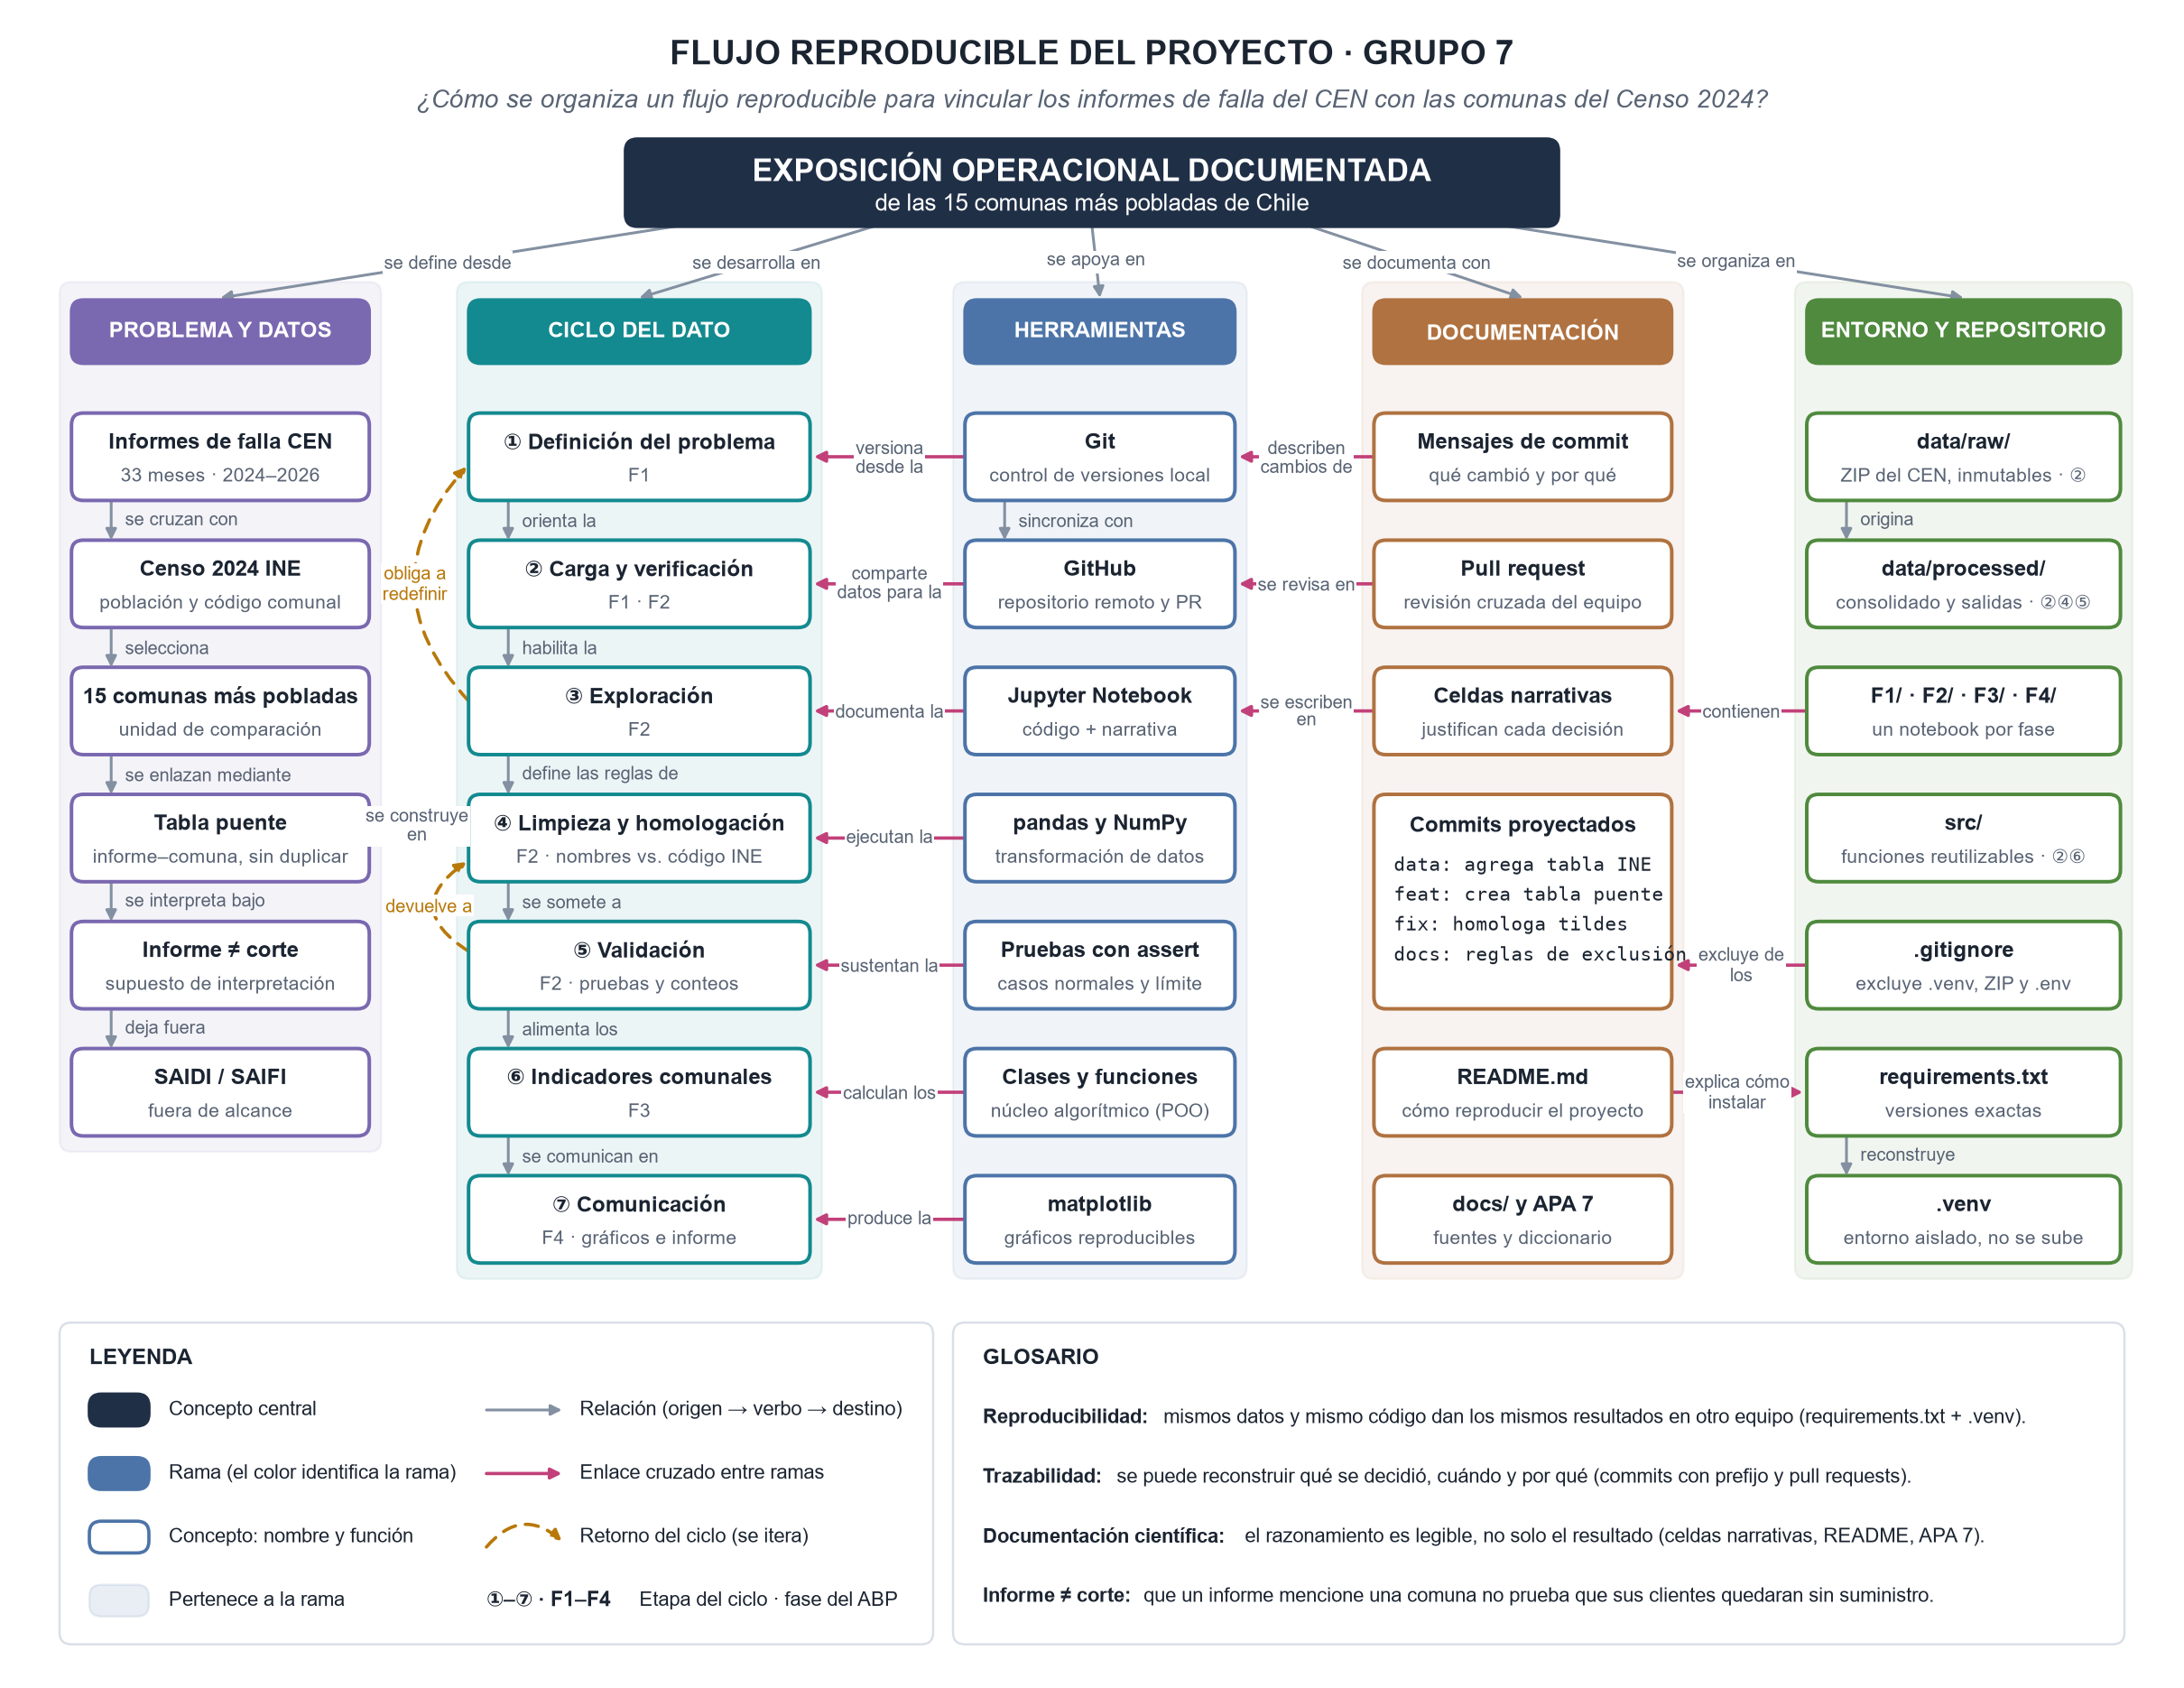

In [4]:
# ==========================================================
# F1 - MAPA CONCEPTUAL TÉCNICO DEL FLUJO REPRODUCIBLE
# Cinco ramas, proposiciones (origen → verbo → destino),
# enlaces cruzados, retornos del ciclo, leyenda y glosario.
# Tamaño carta horizontal: 1 unidad del eje = 1 pulgada.
# ==========================================================
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib import font_manager
from IPython.display import display, Image

# Arial si está instalada (Windows/macOS); Liberation Sans tiene las mismas
# medidas en Linux. DejaVu Sans aporta los símbolos ①–⑦, ≠ y →.
FUENTES = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = [f for f in ("Arial", "Liberation Sans") if f in FUENTES] + ["DejaVu Sans"]

(RAIZ / "docs").mkdir(parents=True, exist_ok=True)
ARCHIVO_MAPA = RAIZ / "docs" / "mapa_conceptual_F1_impacto_comunal.png"
ARCHIVO_MAPA_PDF = ARCHIVO_MAPA.with_suffix(".pdf")

ANCHO, ALTO = 11, 8.5
fig, ax = plt.subplots(figsize=(ANCHO, ALTO))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
fig.patch.set_facecolor("white")
ax.set_xlim(0, ANCHO)
ax.set_ylim(0, ALTO)
ax.axis("off")

C = {"central": "#1F2F46", "texto": "#1B2431", "suave": "#586374",
     "linea": "#8390A1", "cruce": "#C2407A", "retorno": "#B8780A",
     "A": "#7A68B0", "B": "#138A8F", "C": "#4C74A8", "E": "#B07240", "D": "#4F8A3E"}

# Columnas de cada rama: (x izquierda, ancho), en pulgadas.
COLUMNAS = {"A": (0.30, 1.62), "B": (2.30, 1.84), "C": (4.80, 1.48),
            "E": (6.86, 1.62), "D": (9.04, 1.70)}
FILAS = [6.20, 5.56, 4.92, 4.28, 3.64, 3.00, 2.36]   # centro de cada fila
ALTO_NODO, PAD = 0.44, 0.06
N = {}         # clave -> (x0, y0, ancho, alto) de cada nodo
TEXTOS = []    # (texto, ancho disponible): se verifican al final


def caja(x0, y0, ancho, alto, borde, relleno, z=2, grosor=1.2, alfa=1.0):
    """Dibuja un rectángulo redondeado."""
    ax.add_patch(FancyBboxPatch(
        (x0, y0), ancho, alto, boxstyle="round,pad=0,rounding_size=0.06",
        edgecolor=borde, facecolor=relleno, linewidth=grosor, alpha=alfa, zorder=z))


def nodo(clave, rama, fila, titulo, subtitulo, filas=1):
    """Concepto de una rama: nombre en negrita y su función debajo."""
    x, w = COLUMNAS[rama]
    x0, w = x + PAD, w - 2 * PAD
    y_sup = FILAS[fila] + ALTO_NODO / 2
    y_inf = FILAS[fila + filas - 1] - ALTO_NODO / 2
    caja(x0, y_inf, w, y_sup - y_inf, C[rama], "white", z=3, grosor=1.3)
    N[clave] = (x0, y_inf, w, y_sup - y_inf)
    if subtitulo is None:
        return
    yc = FILAS[fila]
    t1 = ax.text(x0 + w / 2, yc + 0.07, titulo, ha="center", va="center",
                 fontsize=8, weight="bold", color=C["texto"], zorder=4)
    t2 = ax.text(x0 + w / 2, yc - 0.10, subtitulo, ha="center", va="center",
                 fontsize=6.8, color=C["suave"], zorder=4)
    TEXTOS.extend([(t1, w - 0.08), (t2, w - 0.08)])


def etiqueta(x, y, texto, ha="center", color=None, fondo=True):
    """Palabra de enlace de un conector."""
    caja_fondo = {"facecolor": "white", "edgecolor": "none", "pad": 0.6} if fondo else None
    ax.text(x, y, texto, ha=ha, va="center", fontsize=6.6, color=color or C["suave"],
            linespacing=1.1, bbox=caja_fondo, zorder=5)


def flecha(p, q, tipo="rel", curva=0.0):
    """Flecha entre dos puntos: relación, enlace cruzado o retorno."""
    estilo = {"rel": (C["linea"], "-", 1.0), "cruce": (C["cruce"], "-", 1.2),
              "retorno": (C["retorno"], (0, (4, 3)), 1.2)}[tipo]
    ax.add_patch(FancyArrowPatch(
        p, q, arrowstyle="-|>", mutation_scale=8, shrinkA=0, shrinkB=0,
        connectionstyle=f"arc3,rad={curva}", color=estilo[0],
        linestyle=estilo[1], linewidth=estilo[2], zorder=2))


def cadena(rama, fila, enlace):
    """Relación vertical entre el nodo de una fila y el de la siguiente."""
    x0 = COLUMNAS[rama][0] + PAD + 0.20
    flecha((x0, FILAS[fila] - ALTO_NODO / 2), (x0, FILAS[fila + 1] + ALTO_NODO / 2))
    etiqueta(x0 + 0.07, (FILAS[fila] + FILAS[fila + 1]) / 2, enlace, ha="left", fondo=False)


def cruce(origen, destino, enlace, dy=0.0):
    """Enlace cruzado horizontal entre ramas vecinas."""
    xo, yo, wo, ho = N[origen]
    xd, yd, wd, hd = N[destino]
    y = yo + ho / 2 + dy if ho < 0.6 else yd + hd / 2 + dy
    if xo < xd:
        p, q = (xo + wo, y), (xd - 0.02, y)
    else:
        p, q = (xo, y), (xd + wd + 0.02, y)
    flecha(p, q, "cruce")
    etiqueta((p[0] + q[0]) / 2, y, enlace)


# --- Título y pregunta de enfoque ----------------------------------------
ax.text(ANCHO / 2, 8.22, "FLUJO REPRODUCIBLE DEL PROYECTO · GRUPO 7", ha="center",
        va="center", fontsize=12, weight="bold", color=C["texto"])
ax.text(ANCHO / 2, 7.99, "¿Cómo se organiza un flujo reproducible para vincular los informes "
        "de falla del CEN con las comunas del Censo 2024?", ha="center", va="center",
        fontsize=9, style="italic", color=C["suave"])

# --- Concepto central y ramas ---------------------------------------------
caja(3.15, 7.36, 4.70, 0.44, C["central"], C["central"], z=3)
ax.text(5.50, 7.645, "EXPOSICIÓN OPERACIONAL DOCUMENTADA", ha="center", va="center",
        fontsize=11, weight="bold", color="white", zorder=4)
ax.text(5.50, 7.47, "de las 15 comunas más pobladas de Chile", ha="center", va="center",
        fontsize=8.5, color="white", zorder=4)

RAMAS = {"A": ("PROBLEMA Y DATOS", "se define desde", 3.40),
         "B": ("CICLO DEL DATO", "se desarrolla en", 4.40),
         "C": ("HERRAMIENTAS", "se apoya en", 5.50),
         "E": ("DOCUMENTACIÓN", "se documenta con", 6.60),
         "D": ("ENTORNO Y REPOSITORIO", "se organiza en", 7.60)}
Y_CABECERA, ALTO_CABECERA = 6.83, 0.32
for rama, (nombre, verbo, x_salida) in RAMAS.items():
    x, w = COLUMNAS[rama]
    filas = 6 if rama == "A" else 7
    y_inf = FILAS[filas - 1] - ALTO_NODO / 2 - 0.08
    caja(x, y_inf, w, 7.08 - y_inf, C[rama], C[rama], z=1, grosor=0.8, alfa=0.08)
    caja(x + PAD, Y_CABECERA - ALTO_CABECERA / 2, w - 2 * PAD, ALTO_CABECERA,
         C[rama], C[rama], z=3)
    t = ax.text(x + w / 2, Y_CABECERA, nombre, ha="center", va="center", fontsize=7.8,
                weight="bold", color="white", zorder=4)
    TEXTOS.append((t, w - 2 * PAD - 0.08))
    destino = (x + w / 2, Y_CABECERA + ALTO_CABECERA / 2 + 0.01)
    flecha((x_salida, 7.36), destino)
    etiqueta((x_salida + destino[0]) / 2, (7.36 + destino[1]) / 2, verbo)

# --- Nodos de cada rama ----------------------------------------------------
CONCEPTOS = {
    "A": [("Informes de falla CEN", "33 meses · 2024–2026"),
          ("Censo 2024 INE", "población y código comunal"),
          ("15 comunas más pobladas", "unidad de comparación"),
          ("Tabla puente", "informe–comuna, sin duplicar"),
          ("Informe ≠ corte", "supuesto de interpretación"),
          ("SAIDI / SAIFI", "fuera de alcance")],
    "B": [("① Definición del problema", "F1"),
          ("② Carga y verificación", "F1 · F2"),
          ("③ Exploración", "F2"),
          ("④ Limpieza y homologación", "F2 · nombres vs. código INE"),
          ("⑤ Validación", "F2 · pruebas y conteos"),
          ("⑥ Indicadores comunales", "F3"),
          ("⑦ Comunicación", "F4 · gráficos e informe")],
    "C": [("Git", "control de versiones local"),
          ("GitHub", "repositorio remoto y PR"),
          ("Jupyter Notebook", "código + narrativa"),
          ("pandas y NumPy", "transformación de datos"),
          ("Pruebas con assert", "casos normales y límite"),
          ("Clases y funciones", "núcleo algorítmico (POO)"),
          ("matplotlib", "gráficos reproducibles")],
    "E": [("Mensajes de commit", "qué cambió y por qué"),
          ("Pull request", "revisión cruzada del equipo"),
          ("Celdas narrativas", "justifican cada decisión"),
          None, None,
          ("README.md", "cómo reproducir el proyecto"),
          ("docs/ y APA 7", "fuentes y diccionario")],
    "D": [("data/raw/", "ZIP del CEN, inmutables · ②"),
          ("data/processed/", "consolidado y salidas · ②④⑤"),
          ("F1/ · F2/ · F3/ · F4/", "un notebook por fase"),
          ("src/", "funciones reutilizables · ②⑥"),
          (".gitignore", "excluye .venv, ZIP y .env"),
          ("requirements.txt", "versiones exactas"),
          (".venv", "entorno aislado, no se sube")],
}
for rama, lista in CONCEPTOS.items():
    for fila, concepto in enumerate(lista):
        if concepto is not None:
            nodo(f"{rama}{fila + 1}", rama, fila, *concepto)

# Caja de commits proyectados (rama Documentación, filas 4 y 5).
nodo("E4", "E", 3, None, None, filas=2)
x0, y0, w, h = N["E4"]
ax.text(x0 + w / 2, y0 + h - 0.16, "Commits proyectados", ha="center", va="center",
        fontsize=8, weight="bold", color=C["texto"], zorder=4)
for k, commit in enumerate(["data: agrega tabla INE", "feat: crea tabla puente",
                            "fix: homologa tildes", "docs: reglas de exclusión"]):
    t = ax.text(x0 + 0.10, y0 + h - 0.36 - k * 0.15, commit, ha="left", va="center",
                fontsize=6.8, family="DejaVu Sans Mono", color=C["texto"], zorder=4)
    TEXTOS.append((t, w - 0.14))

# --- Relaciones dentro de cada rama ----------------------------------------
for fila, enlace in enumerate(["se cruzan con", "selecciona", "se enlazan mediante",
                               "se interpreta bajo", "deja fuera"]):
    cadena("A", fila, enlace)
for fila, enlace in enumerate(["orienta la", "habilita la", "define las reglas de",
                               "se somete a", "alimenta los", "se comunican en"]):
    cadena("B", fila, enlace)
cadena("C", 0, "sincroniza con")
cadena("D", 0, "origina")
cadena("D", 5, "reconstruye")

# --- Retornos del ciclo: el flujo no es lineal -------------------------------
xb = N["B1"][0]
flecha((xb, FILAS[2] + 0.05), (xb - 0.01, FILAS[0] - 0.05), "retorno", curva=-0.45)
etiqueta(xb - 0.27, (FILAS[0] + FILAS[2]) / 2, "obliga a\nredefinir", color=C["retorno"])
flecha((xb, FILAS[4] + 0.07), (xb - 0.01, FILAS[3] - 0.12), "retorno", curva=-0.75)
etiqueta(xb - 0.20, (FILAS[3] + FILAS[4]) / 2 - 0.02, "devuelve a", color=C["retorno"])

# --- Enlaces cruzados --------------------------------------------------------
# Cada herramienta se une con la etapa del ciclo donde actúa.
for fila, enlace in enumerate(["versiona\ndesde la", "comparte\ndatos para la",
                               "documenta la", "ejecutan la", "sustentan la",
                               "calculan los", "produce la"]):
    cruce(f"C{fila + 1}", f"B{fila + 1}", enlace)
# La documentación se vincula con herramientas y repositorio.
cruce("E1", "C1", "describen\ncambios de")
cruce("E2", "C2", "se revisa en")
cruce("E3", "C3", "se escriben\nen")
cruce("D3", "E3", "contienen")
cruce("D5", "E4", "excluye de\nlos")
cruce("E6", "D6", "explica cómo\ninstalar")
# El problema se materializa en una etapa del ciclo.
cruce("A4", "B4", "se construye\nen", dy=0.06)

# --- Leyenda -------------------------------------------------------------------
caja(0.30, 0.22, 4.40, 1.62, "#D9DFE7", "white", z=1, grosor=0.8)
ax.text(0.45, 1.66, "LEYENDA", fontsize=8, weight="bold", color=C["texto"], va="center")
muestras = [("central", "Concepto central"), ("rama", "Rama (el color identifica la rama)"),
            ("nodo", "Concepto: nombre y función"), ("grupo", "Pertenece a la rama")]
for k, (tipo, texto) in enumerate(muestras):
    y = 1.40 - k * 0.32
    if tipo == "central":
        caja(0.45, y - 0.08, 0.30, 0.16, C["central"], C["central"], z=3)
    elif tipo == "rama":
        caja(0.45, y - 0.08, 0.30, 0.16, C["C"], C["C"], z=3)
    elif tipo == "nodo":
        caja(0.45, y - 0.08, 0.30, 0.16, C["C"], "white", z=3)
    else:
        caja(0.45, y - 0.08, 0.30, 0.16, C["C"], C["C"], z=3, grosor=0.8, alfa=0.12)
    ax.text(0.85, y, texto, fontsize=7.3, va="center", color=C["texto"])
lineas = [("rel", "Relación (origen → verbo → destino)"),
          ("cruce", "Enlace cruzado entre ramas"),
          ("retorno", "Retorno del ciclo (se itera)")]
for k, (tipo, texto) in enumerate(lineas):
    y = 1.40 - k * 0.32
    if tipo == "retorno":
        flecha((2.45, y - 0.05), (2.83, y - 0.02), "retorno", curva=-0.5)
    else:
        flecha((2.45, y), (2.83, y), tipo)
    t = ax.text(2.92, y, texto, fontsize=7.3, va="center", color=C["texto"])
    TEXTOS.append((t, 4.66 - 2.92))
ax.text(2.45, 0.44, "①–⑦ · F1–F4", fontsize=7.5, weight="bold", va="center", color=C["texto"])
ax.text(3.22, 0.44, "Etapa del ciclo · fase del ABP", fontsize=7.3, va="center",
        color=C["texto"])

# --- Glosario: distingue los tres conceptos de la Fase 1 -------------------------
caja(4.80, 0.22, 5.90, 1.62, "#D9DFE7", "white", z=1, grosor=0.8)
ax.text(4.95, 1.66, "GLOSARIO", fontsize=8, weight="bold", color=C["texto"], va="center")
fig.canvas.draw()
render = fig.canvas.get_renderer()
glosario = [("Reproducibilidad:", "mismos datos y mismo código dan los mismos resultados "
             "en otro equipo (requirements.txt + .venv)."),
            ("Trazabilidad:", "se puede reconstruir qué se decidió, cuándo y por qué "
             "(commits con prefijo y pull requests)."),
            ("Documentación científica:", "el razonamiento es legible, no solo el "
             "resultado (celdas narrativas, README, APA 7)."),
            ("Informe ≠ corte:", "que un informe mencione una comuna no prueba que sus "
             "clientes quedaran sin suministro.")]
for k, (termino, definicion) in enumerate(glosario):
    y = 1.36 - k * 0.30
    t = ax.text(4.95, y, termino, fontsize=7.2, weight="bold", va="center", color=C["texto"])
    fin = t.get_window_extent(render).transformed(ax.transData.inverted()).x1
    t2 = ax.text(fin + 0.05, y, definicion, fontsize=7.2, va="center", color=C["texto"])
    TEXTOS.append((t2, 10.62 - (fin + 0.05)))

# --- Verificación: ningún texto sobrepasa su caja ---------------------------------
fig.canvas.draw()
render = fig.canvas.get_renderer()
desbordes = []
for texto, disponible in TEXTOS:
    ancho = texto.get_window_extent(render).transformed(ax.transData.inverted()).width
    if ancho > disponible:
        desbordes.append((texto.get_text(), round(ancho, 2), round(disponible, 2)))
assert not desbordes, f"Textos que no caben en su caja: {desbordes}"

fig.savefig(ARCHIVO_MAPA, dpi=220, facecolor="white")
fig.savefig(ARCHIVO_MAPA_PDF, facecolor="white")
plt.close(fig)
print(f"[OK] {len(TEXTOS)} textos verificados: ninguno sobrepasa su caja")
print("MAPA CONCEPTUAL GENERADO (carta horizontal, 11 × 8,5 in):")
print(" ", ARCHIVO_MAPA.relative_to(RAIZ))
print(" ", ARCHIVO_MAPA_PDF.relative_to(RAIZ))
display(Image(filename=str(ARCHIVO_MAPA), width=1100))

### 9.2. Vinculación del mapa conceptual con evidencias verificables

| Concepto | Producto o archivo | Estado |
|---|---|---|
| **Informes de falla del CEN** | 33 ZIP de origen y script `src/consolidar_fallas_2024_2026.py` | Integración inicial desarrollada |
| **Trazabilidad documental** | `id_falla`, fechas de publicación, archivo/fila de origen | Disponible en el consolidado; revisión en F2 |
| **Comuna mencionada** | Campo `Comuna` y diagnóstico de cobertura en F1 | Verificación inicial; sin homologación INE |
| **Consumo reportado** | Campo `Consumo` y distribución inicial | Verificación inicial; reglas finales en F2 |
| **Territorio y población INE** | Tabla de población y códigos comunales del Censo 2024 | Fuente identificada; integración pendiente F2 |
| **Selección de 15 comunas** | Ordenamiento poblacional nacional con criterios explícitos | Pendiente de ejecución F2 |
| **Relación informe–comuna** | Tabla puente con expansión `|` y código oficial | Pendiente F2 |
| **Control de calidad** | Verificaciones F1 y pruebas sintéticas | Inicial ejecutable; pipeline completo pendiente F2 |
| **Exposición operacional** | Conteos de informes únicos y consumo afectado por comuna | Proyectado F3 |
| **Duraciones documentales** | Fechas técnicamente válidas y cobertura de cálculo | Preprocesamiento F2; análisis F3 |
| **Impacto en usuarios/SAIDI/SAIFI** | Requiere clientes interrumpidos y tiempo efectivo de cada interrupción | Fuera de la medición directa actual |
| **Comunicación** | Visualizaciones, interpretación y recomendaciones | Proyectado F4 |

### 9.3. Relaciones conceptuales decisivas

**«Informe de falla → menciona → comuna»** se implementará mediante una asociación muchos-a-muchos; mencionar cuatro comunas no crea cuatro nuevos informes originales. **«Comuna → se caracteriza por → población censada»** permitirá seleccionar 15 unidades territoriales con criterios independientes de la cantidad de fallas reportadas.

**«Informe → clasifica → consumo reportado»** es necesario para no atribuir afectación a casos con `consumo_no_afectado`. **«Registros validados → sustentan → indicadores comunales»** exige identificar estados, duraciones y cobertura antes de interpretar un ranking.

**«Indicadores de informes → no equivalen a → SAIDI/SAIFI»** representa el límite principal del estudio. Su presencia explícita en el mapa evita presentar una comparación documental como medición directa de interrupciones de clientes. La correspondencia entre mapa, notebook, futuro F2, README e informe institucional será comprobada al cierre del entregable.

## 10. Control de versiones, reproducibilidad y trazabilidad del proyecto

### 10.1. Repositorio y estructura colaborativa

El repositorio utilizado es **`jeanpaulsalasmeneses-lab/Proyecto_MCDI500`**. Git/GitHub registra versiones de notebooks, funciones, reglas de homologación y documentos. La evidencia de trabajo colaborativo se comprobará mediante **commits atribuibles a cada integrante**; compartir acceso no equivale a demostrar aportes.

La organización proyectada contempla `F1/`, `F2/`, `src/`, `docs/`, `data/raw/` y `data/processed/`, un README actualizado y un archivo `requirements.txt`. El tratamiento de información original y derivada debe distinguir archivos que se publican en GitHub de aquellos que se reconstruyen localmente.

### 10.2. Registro de cambios conceptuales

La investigación tuvo una primera formulación vinculada con alumbrado público, luego se orientó a patrones de fallas y confiabilidad del SEN y, finalmente, se delimitó a **exposición operacional documentada de comunas prioritarias**. Este último ajuste **no es únicamente un cambio de título**: modifica la pregunta central, objetivos, variables, metodología, mapa conceptual y criterios de calidad.

La decisión se fundamenta en la presencia comprobada de campos `Comuna` y `Consumo` en archivos originales del CEN y en la disponibilidad de población comunal del Censo 2024. En el historial deberá constar la razón del cambio y la diferencia entre exposición documental e interrupciones de usuarios.

### 10.3. Evidencias y archivos esperados

| Evidencia | Ubicación prevista | Verificación |
|---|---|---|
| Notebook F1 actualizado | `F1/F1_Definición.ipynb` | Narrativa territorial, diagnóstico y mapa |
| Consolidador histórico | `src/consolidar_fallas_2024_2026.py` | Integración de ZIP, trazabilidad documental |
| Dataset documental | `data/processed/cen_fallas_2024_2026_eventos.csv` | Lectura y validación estructural; puede ser local |
| Mapa territorial conceptual | `docs/mapa_conceptual_F1_impacto_comunal.png` | Relaciones CEN–INE–consumo–indicadores |
| Maestro comunal | `data/external/...` (ruta por fijar en F2) | Origen INE, código y población verificables |
| Notebook F2 | `F2/F2_Exploracion_y_Preprocesamiento.ipynb` | Pipeline y tablas de relación territorial; **pendiente** |
| Documentación | `README.md`, `requirements.txt` | Instrucciones de reproducción |
| Registro de pruebas | Celdas F1/F2, salidas y commits | Casos normales, límite y excepciones |

### 10.4. Reconstrucción reproducible

Un colaborador deberá poder instalar las dependencias, reconstruir el dataset del CEN desde los ZIP originales, incorporar el conjunto oficial comunal INE y ejecutar los notebooks por orden. Se conservará una copia de los datos originales y una descripción de transformaciones; no se sobrescribirán las fuentes de entrada. Barker et al. (2022) fundamentan este enfoque al destacar procedencia, dependencias y reutilización del software científico.

Los datos crudos pueden no estar incluidos en GitHub por tamaño o por decisiones de publicación; el README debe señalar cómo descargarlos y reconstruir las entradas. **F1 requiere el CSV consolidado para ejecutar la comprobación de contenido**, por lo que la reconstrucción debe preceder a la ejecución completa cuando el archivo no esté disponible.

### 10.5. Comprobaciones de cierre

Se verificará la ejecución desde la primera hasta la última celda, el archivo de figura, la coincidencia de rutas, la vigencia de las citas bibliográficas, el historial de GitHub y la separación de funciones entre F1 y F2. Los resultados guardados del enfoque anterior **no se consideran pruebas suficientes** tras esta reformulación.

La rúbrica exige un informe institucional PDF integrado F1–F2; este notebook constituye la evidencia reproducible **exclusiva de F1**, no el informe final.

## 11. Referencias bibliográficas (APA 7.ª edición)

Las siguientes fuentes se utilizan porque sustentan **decisiones específicas del análisis**: diferenciar interrupciones de clientes y fallas técnicas, seleccionar comunas por población, interpretar categorías de consumo, preparar datos y asegurar reproducibilidad. No reemplazan los dos materiales docentes reales que exige la evaluación.

Barker, M., Chue Hong, N. P., Katz, D. S., Lamprecht, A.-L., Martinez-Ortiz, C., Psomopoulos, F., Harrow, J., Castro, L. J. G., Gruenpeter, M., Martinez, P. A., & Honeyman, T. (2022). Introducing the FAIR principles for research software. *Scientific Data, 9*, artículo 622. https://doi.org/10.1038/s41597-022-01710-x

Comisión Nacional de Energía. (2024). *Norma técnica de calidad de servicio para sistemas de distribución*. https://www.cne.cl/normativas/electrica/normas-tecnicas/ntcsdx2024/

Coordinador Eléctrico Nacional. (s. f.). *Desconexiones e intervenciones / informes de falla / limitaciones* [Conjunto de datos]. https://www.coordinador.cl/operacion/graficos/desconexiones-e-intervenciones/

Instituto Nacional de Estadísticas. (2025). *Resultados del Censo de Población y Vivienda 2024*. https://censo2024.ine.gob.cl/resultados/

Novak, J. D., & Cañas, A. J. (2008). *The theory underlying concept maps and how to construct and use them* (Technical Report IHMC CmapTools 2006-01 Rev 01-2008). Florida Institute for Human and Machine Cognition.

pandas development team. (s. f.-a). *pandas.to_datetime*. *pandas documentation*. https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html

pandas development team. (s. f.-b). *Working with missing data*. *pandas documentation*. https://pandas.pydata.org/docs/user_guide/missing_data.html

Python Software Foundation. (s. f.). *venv — Creation of virtual environments*. *Python 3.13 documentation*. https://docs.python.org/3.13/library/venv.html

Silva, M. K. da, Lopes, R. S., Fontana, M. E., & Almeida, J. K. B. de. (2025). A data-driven approach to maintenance-preventable causes of failure analysis in power distribution systems. *Brazilian Journal of Operations & Production Management, 22*(3), artículo 2702. https://doi.org/10.14488/BJOPM.2702.2025

Superintendencia de Electricidad y Combustibles. (s. f.). *Interrupciones eléctricas – SAIDI*. https://www.sec.cl/informe-sec-saidi/

Universidad de Chile. (s. f.). *¿Cómo hacer un mapa conceptual?* https://aprendizaje.uchile.cl/recursos-para-leer-escribir-y-hablar-en-la-universidad/profundiza/lectura/mapa/

### 11.1. Material docente de MCDI500 pendiente de incorporación

La entrega exige **al menos dos referencias de los recursos docentes de la semana 1**. Se incorporarán después de examinar sus documentos reales y vincular conceptos concretos con el texto o con el código. No se simularán citas a material que no se haya revisado.